# BiciMAD infrastructure evolution

This notebook follows how the physical BiciMAD network changed. It starts with the number of stations EMT listed in each status snapshot.


## 0. Setup


In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

HERE = Path.cwd().resolve()
ROOT = HERE
for _candidate in (HERE, *HERE.parents):
    if (_candidate / "src" / "bicimad" / "__init__.py").is_file():
        ROOT = _candidate
        break
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

from bicimad.config import MADRID_TZ, ProjectConfig
from bicimad.download import ensure_status_files
from bicimad.ingest import load_snapshot_station_counts

cfg = ProjectConfig()
print("project root:", cfg.root)


project root: C:\Users\jejoz\Coding\TFG\v1


## 1. Stations in the network over time

The EMT historical package publishes a snapshot of every station about once an hour. At snapshot time $t$ the size of the network is

$$
N(t) = |\{\text{stations listed in the EMT status snapshot at } t\}|.
$$

A station is active when the snapshot field `activate` equals 1. EMT can keep listing a station that is out of service, so the two counts are kept separate.

The plotted series is the median of each count inside a calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The download below takes only the station-status members of the 2017–2023 archives. Trip files stay on the server. A file already in `data/raw/status` is left as it is, and the snapshot counts are cached under `data/processed/infrastructure`.


In [2]:
report = ensure_status_files(cfg)
counts = load_snapshot_station_counts(cfg)

months = sorted(counts["month"].unique())
span = pd.period_range(months[0], months[-1], freq="M")
missing = [str(period) for period in span if str(period) not in set(months)]
unpublished = (
    report.loc[report["action"].eq("not published"), "year"].astype(int).tolist()
)
print(f"snapshots: {len(counts):,}")
print(f"status months: {months[0]} to {months[-1]} ({len(months)} months)")
print("months missing inside that span:", missing or "none")
print("yearly archives with no status files:", unpublished)


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


EMT 2022: listing https://media.emtmadrid.es/-uHaW6iZkhG


EMT 2023: listing https://media.emtmadrid.es/-9Nii5DXo4x


EMT 2023: archive has no station-status files.


snapshots: 39,252
status months: 2018-07 to 2022-12 (54 months)
months missing inside that span: none
yearly archives with no status files: [2017, 2023]


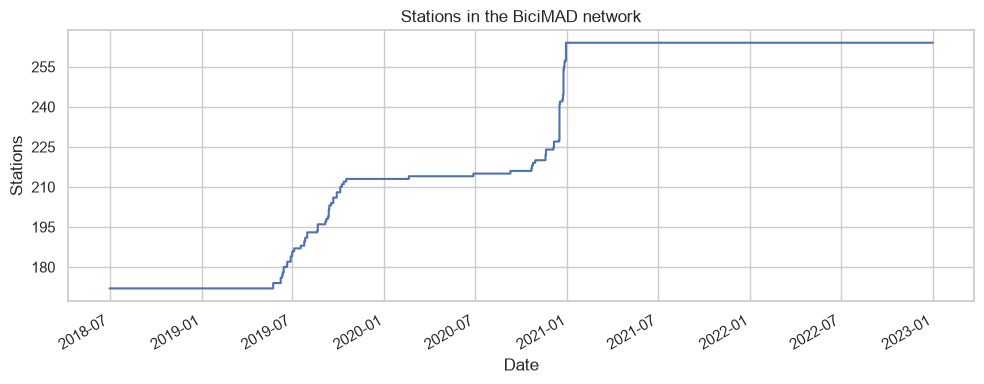

In [3]:
local_day = counts["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    counts.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_stations=("n_stations", "median"), n_active=("n_active", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily["n_stations"] = _as_count(daily["n_stations"])
daily["n_active"] = _as_count(daily["n_active"])

calendar = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)
active_differs = bool(
    (
        plot["n_stations"].notna()
        & plot["n_active"].notna()
        & plot["n_stations"].ne(plot["n_active"])
    ).any()
)

fig, ax = plt.subplots()
x = plot.index.tz_localize(None)
ax.step(x, plot["n_stations"], where="post", label="Listed in the snapshot")
if active_differs:
    ax.step(x, plot["n_active"], where="post", label="Active (activate = 1)")
    ax.legend(frameon=False)
ax.set_title("Stations in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Stations")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [4]:
listed_changed = daily["n_stations"].diff().fillna(0).ne(0)
active_changed = daily["n_active"].diff().fillna(0).ne(0)
presence_changed = daily["n_active"].isna().astype(int).diff().fillna(0).ne(0)
changed = listed_changed | active_changed | presence_changed
changed.iloc[0] = True

changes = daily.loc[changed, ["date", "n_stations", "n_active"]].copy()
changes["change"] = changes["n_stations"].diff()
changes["date"] = changes["date"].dt.strftime("%Y-%m-%d")
changes = changes.rename(columns={"n_stations": "listed", "n_active": "active"})
changes


,date,listed,active,change
0,2018-07-01,172.0,172.0,<NA>
327,2019-05-24,174.0,174.0,2.0
342,2019-06-08,176.0,176.0,2.0
345,2019-06-11,177.0,177.0,1.0
346,2019-06-12,178.0,178.0,1.0
348,2019-06-14,180.0,180.0,2.0
354,2019-06-20,180.5,180.5,0.5
355,2019-06-21,182.0,182.0,1.5
362,2019-06-28,184.0,184.0,2.0
365,2019-07-01,185.5,185.5,1.5


## 2. Reading the series

From 1 July 2018 through 1 January 2023 the daily median rises from 172 stations to 264. Every step in the table is an increase. On every snapshot the active count equals the listed count, so `activate` is 1 for every station in these files.

The median stays at 172 until 24 May 2019. It then rises through the rest of 2019 and reaches 213 on 17 October 2019. The next additions are 214 on 19 February 2020, 215 on 27 June 2020, and 216 on 9 September 2020. From 21 October 2020 to 29 December 2020 the median climbs from 217 to 264. The largest one-day rises are 13.5 stations on 16 December 2020, to 241, then 9.5 on 24 December 2020, to 254, and 6.5 on 29 December 2020, to 264. A half station is a day whose hourly snapshots were split between two counts, so the median lies halfway between them. From 29 December 2020 through 1 January 2023 the median stays at 264. The table lists every day the median changes.

The status files cover every month from July 2018 through December 2022. The 2017 archive and the 2023 archive contain no station-status files, and the 2018 archive begins in July. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot. The point on 1 January 2023 is the single snapshot at 00:57 local time at the end of the December 2022 file.
